# A/B Testing Analysis

### Эксперимент · Конверсия · Размер эффекта · Бизнес-решение

Исследование результатов сравнения старой и новой страниц на основе
[учебного датасета A/B Testing](https://www.kaggle.com/datasets/zhangluyuan/ab-testing).

**Цель:** оценить изменение конверсии, проверить статистическую значимость
и определить, поддерживают ли данные внедрение новой страницы.

**Источник:** публичный учебный датасет с Kaggle. Результаты не относятся
к эксперименту реальной компании.

| Особенность | Как учитываем |
|---|---|
| Одна строка — запись события | Для анализа оставляем уникальных пользователей |
| Control (A) | Старая страница: `control` → `old_page` |
| Treatment (B) | Новая страница: `treatment` → `new_page` |
| Основная метрика | Доля пользователей с `converted = 1` |
| Уровень значимости | 5%, двусторонний z-тест |
| Бизнес-порог | Рост на 1 процентный пункт — учебное допущение |
| Баланс групп | Условная проверка при ожидаемом распределении 50/50 |

## Содержание

1. Загрузка и обзор данных
2. Подготовка данных
3. Баланс групп и качество эксперимента
4. Конверсия и размер эффекта
5. Статистическая проверка гипотез
6. Доверительный интервал
7. Визуализация результатов
8. Практическая значимость
9. Выводы и рекомендации

**Запуск:** CSV должен лежать в `data/ab_data.csv` рядом с папкой ноутбука.
Выберите Python kernel и выполните **Run All**. Недостающие библиотеки
устанавливаются автоматически; графики сохраняются в `images/`.


## 1. Загрузка и обзор данных

Загружаем исходную таблицу и проверяем размер, примеры строк и типы столбцов.
Исходный `df` сохраняем для сверки. Параметры теста задаём до просмотра результата.


In [1]:
# Устанавливаем только недостающие библиотеки в выбранное Python-окружение.
import importlib.util
import subprocess
import sys

packages = ["pandas", "numpy", "scipy", "matplotlib", "seaborn"]
missing = [name for name in packages if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])


In [2]:
# Импортируем библиотеки для таблиц, статистики и графиков.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown


In [3]:
# Фиксируем пороги и задаём единый стиль: синий и оранжевый цвета, белый фон.
ALPHA = 0.05
BUSINESS_THRESHOLD = 0.01
SRM_ALPHA = 0.01
EXPECTED_A_SHARE = 0.5  # Допущение: плановое распределение 50/50 неизвестно из CSV.
GROUPS = ["control", "treatment"]
LABELS = ["Контроль (A)", "Тест (B)"]
COLORS = ["steelblue", "orange"]

plt.rcdefaults()
plt.rcParams.update({"figure.dpi": 110, "font.family": "DejaVu Sans"})
pd.options.display.float_format = "{:,.4f}".format

print("Библиотеки готовы. Python:", sys.version.split()[0])


Библиотеки готовы. Python: 3.14.7


In [4]:
# Находим CSV и создаём папку для сохранения графиков.
candidates = [Path.cwd() / "data" / "ab_data.csv", Path.cwd() / "ab_data.csv",
              Path.cwd().parent / "data" / "ab_data.csv"]
DATA_PATH = next((p for p in candidates if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Не найден ab_data.csv. Поместите его в data/ рядом с ноутбуком и выполните Run All.")

PROJECT_DIR = DATA_PATH.parent.parent if DATA_PATH.parent.name == "data" else DATA_PATH.parent
IMAGE_DIR = PROJECT_DIR / "images"
IMAGE_DIR.mkdir(exist_ok=True)

df = pd.read_csv(DATA_PATH)
required = ["user_id", "timestamp", "group", "landing_page", "converted"]
if not set(required).issubset(df.columns):
    raise ValueError(f"В CSV отсутствуют колонки: {set(required) - set(df.columns)}")


In [5]:
# Выводим размер загруженной таблицы; исходные данные не изменяем.
# Сохраняем исходную таблицу df; изменения делаем в отдельных копиях.
print(f"Файл: {DATA_PATH.name} | Строк: {len(df):,} | Столбцов: {df.shape[1]}")


Файл: ab_data.csv | Строк: 294,478 | Столбцов: 5


In [6]:
# Первые пять строк помогают понять устройство данных.
display(df.head())


,user_id,timestamp,group,landing_page,converted
0,851104,2017-01-21 22:11:48.556739,control,old_page,0
1,804228,2017-01-12 08:01:45.159739,control,old_page,0
2,661590,2017-01-11 16:55:06.154213,treatment,new_page,0
3,853541,2017-01-08 18:28:03.143765,treatment,new_page,0
4,864975,2017-01-21 01:52:26.210827,control,old_page,1


In [7]:
# Проверяем типы столбцов и число заполненных значений.
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 294478 entries, 0 to 294477
Data columns (total 5 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   user_id       294478 non-null  int64
 1   timestamp     294478 non-null  str  
 2   group         294478 non-null  str  
 3   landing_page  294478 non-null  str  
 4   converted     294478 non-null  int64
dtypes: int64(2), str(3)
memory usage: 11.2 MB


## 2. Подготовка данных

Проверяем пропуски, повторы пользователей, значения конверсии и соответствие
группы странице. Эти проверки проводим до сравнения результатов эксперимента.


In [8]:
# Создаём рабочую копию и преобразуем даты и значения конверсии.
work = df.copy()
# Некорректная дата превращается в NaT, чтобы ошибка была видна в отчёте.
work["timestamp"] = pd.to_datetime(work["timestamp"], errors="coerce")
work["converted"] = pd.to_numeric(work["converted"], errors="coerce")


In [9]:
# Считаем потенциально проблемные записи, пока ничего не удаляем.
display(work[required].isna().sum().rename("missing_or_invalid").to_frame())
print("Полные дубликаты строк:", int(work.duplicated().sum()))
print("Уникальных user_id:", work["user_id"].nunique())
print("Повторных user_id (строк сверх первой):", int(work["user_id"].dropna().duplicated().sum()))
display(pd.crosstab(work["group"], work["landing_page"], dropna=False))
display(work["converted"].value_counts(dropna=False).rename("rows").to_frame())


,missing_or_invalid
user_id,0
timestamp,0
group,0
landing_page,0
converted,0


Полные дубликаты строк: 0
Уникальных user_id: 290584
Повторных user_id (строк сверх первой): 3894


landing_page,new_page,old_page
group,,
control,1928,145274
treatment,145311,1965


,rows
converted,
0,259241
1,35237


In [10]:
# Находим пользователей, наблюдавшихся сразу в двух группах.
valid_groups = work["group"].isin(GROUPS)
cross_group_ids = work.loc[valid_groups].groupby("user_id")["group"].nunique()
cross_group_ids = cross_group_ids[cross_group_ids > 1].index
print("Пользователей в двух группах:", len(cross_group_ids))


Пользователей в двух группах: 1895


### 2.1. Правила очистки и журнал исключений

Полные повторы удаляем. Пользователей с некорректными записями, пересечением
групп, неправильной страницей или несколькими различными событиями исключаем целиком.
Без описания окна конверсии нельзя произвольно выбирать первое или последнее событие.


In [11]:
# Функция фильтрации сохраняет число исключённых строк на каждом шаге.
audit = []
clean = work.copy()

def apply_filter(frame, keep, reason):
    result = frame.loc[keep].copy()
    audit.append({"Этап": reason, "Исключено строк": len(frame) - len(result),
                  "Осталось строк": len(result), "Осталось пользователей": result["user_id"].nunique()})
    return result


In [12]:
# Удаляем полные повторы и исключаем пользователей с некорректными данными или пересечением групп.
clean = apply_filter(clean, ~clean.duplicated(), "Полные дубликаты строк")
invalid = (clean[required].isna().any(axis=1)
           | ~clean["group"].isin(GROUPS)
           | ~clean["landing_page"].isin(["old_page", "new_page"])
           | ~clean["converted"].isin([0, 1]))
invalid_ids = clean.loc[invalid, "user_id"].dropna().unique()
clean = apply_filter(clean, ~invalid & ~clean["user_id"].isin(invalid_ids), "Пользователи с пропусками или некорректными записями")
clean = apply_filter(clean, ~clean["user_id"].isin(cross_group_ids), "Пользователи в двух группах")


In [13]:
# Исключаем неверные страницы и повторные события; сохраняем базу для проверки баланса.
# База диагностики размеров до удаления неправильных страниц и повторных событий.
before_cleaning_users = clean[["user_id", "group"]].drop_duplicates()
page_ok = ((clean["group"] == "control") & (clean["landing_page"] == "old_page")) | (
           (clean["group"] == "treatment") & (clean["landing_page"] == "new_page"))
wrong_page_ids = clean.loc[~page_ok, "user_id"].unique()
clean = apply_filter(clean, ~clean["user_id"].isin(wrong_page_ids), "Несоответствие группы и страницы")
repeat_ids = clean.loc[clean["user_id"].duplicated(keep=False), "user_id"].unique()
clean = apply_filter(clean, ~clean["user_id"].isin(repeat_ids), "Несколько различных событий пользователя")
clean["converted"] = clean["converted"].astype(int)


In [14]:
# Показываем журнал исключений и сравниваем потери пользователей между группами.
audit_table = pd.DataFrame(audit)
display(audit_table)
if clean.empty or set(clean["group"].unique()) != set(GROUPS):
    raise ValueError("После очистки отсутствует одна из групп. Проверьте CSV и журнал исключений.")
assert clean["user_id"].is_unique
assert clean[required].notna().all().all()
assert clean["converted"].isin([0, 1]).all()

retention = pd.concat([
    before_cleaning_users.groupby("group").size().rename("users_before_page_cleanup"),
    clean.groupby("group").size().rename("users_after_cleanup")
], axis=1).reindex(GROUPS)
retention["removed_share_pct"] = (1 - retention["users_after_cleanup"] / retention["users_before_page_cleanup"]) * 100
display(retention)
print(f"В анализе: {len(clean):,} пользователей; исключено строк: {len(df) - len(clean):,}.")


,Этап,Исключено строк,Осталось строк,Осталось пользователей
0,Полные дубликаты строк,0,294478,290584
1,Пользователи с пропусками или некорректными за...,0,294478,290584
2,Пользователи в двух группах,3790,290688,288689
3,Несоответствие группы и страницы,3996,286692,286691
4,Несколько различных событий пользователя,2,286690,286690


,users_before_page_cleanup,users_after_cleanup,removed_share_pct
group,,,
control,144300,143293,0.6979
treatment,144389,143397,0.6870


В анализе: 286,690 пользователей; исключено строк: 7,788.


**Правило очистки:** единица основного анализа — уникальный пользователь.
Журнал показывает дополнительные исключения на каждом шаге. Очистка может изменить
состав выборки и сама по себе не доказывает отсутствие смещения.


## 3. Баланс групп и качество эксперимента

Проверяем размеры групп до и после очистки критерием согласия χ².
При ожидаемом распределении 50/50 сильный дисбаланс может указывать
на ошибку назначения пользователей или потери данных.


In [15]:
# Рассчитываем условную диагностику Sample Ratio Mismatch (SRM).
def srm_result(frame, stage):
    counts = frame.groupby("group").size().reindex(GROUPS, fill_value=0)
    expected = counts.sum() * np.array([EXPECTED_A_SHARE, 1 - EXPECTED_A_SHARE])
    if min(expected) < 5:
        raise ValueError("Слишком мало пользователей для SRM через χ².")
    result = stats.chisquare(counts.to_numpy(), f_exp=expected)
    return {"stage": stage, "A_users": int(counts.iloc[0]), "B_users": int(counts.iloc[1]),
            "p_value": float(result.pvalue), "mismatch_flag": bool(result.pvalue < SRM_ALPHA)}


In [16]:
# Сравниваем результаты диагностики до и после очистки.
srm_table = pd.DataFrame([srm_result(before_cleaning_users, "До очистки страниц и повторов"),
                          srm_result(clean, "После очистки")])
display(srm_table)
srm_flag = bool(srm_table["mismatch_flag"].any())
print("Обнаружен условный SRM: нужно расследование." if srm_flag else
      "При допущении 50/50 значимый дисбаланс не обнаружен; это не гарантия корректности эксперимента.")


,stage,A_users,B_users,p_value,mismatch_flag
0,До очистки страниц и повторов,144300,144389,0.8684,False
1,После очистки,143293,143397,0.8460,False


При допущении 50/50 значимый дисбаланс не обнаружен; это не гарантия корректности эксперимента.


**Ограничение:** плановая пропорция и полный журнал назначения неизвестны.
Проверка 50/50 условна; отсутствие SRM не гарантирует корректную рандомизацию.
При обнаружении дисбаланса решение о внедрении требует расследования.


## 4. Конверсия и размер эффекта

Конверсию считаем как число пользователей с результатом 1, делённое
на размер группы. Абсолютный эффект B − A измеряем в процентных пунктах,
относительный — в процентах от конверсии A.


In [17]:
# Для каждой группы считаем пользователей, конверсии и долю успешных событий.
summary = clean.groupby("group").agg(users=("user_id", "size"), conversions=("converted", "sum")).reindex(GROUPS)
summary["non_conversions"] = summary["users"] - summary["conversions"]
summary["conversion_rate"] = summary["conversions"] / summary["users"]
summary["conversion_rate_pct"] = summary["conversion_rate"] * 100
display(summary)


,users,conversions,non_conversions,conversion_rate,conversion_rate_pct
group,,,,,
control,143293,17220,126073,0.1202,12.0173
treatment,143397,17025,126372,0.1187,11.8726


In [18]:
# Рассчитываем абсолютный и относительный эффект новой страницы.
n_a, n_b = summary["users"].to_numpy(dtype=int)
x_a, x_b = summary["conversions"].to_numpy(dtype=int)
cr_a, cr_b = summary["conversion_rate"].to_numpy()
effect = cr_b - cr_a
relative_lift = effect / cr_a if cr_a > 0 else np.nan
print(f"Control: {cr_a:.2%}; Treatment: {cr_b:.2%}")
print(f"Абсолютный эффект B − A: {effect * 100:+.4f} п.п.")
print(f"Относительный эффект: {relative_lift:+.2%}" if cr_a > 0 else "Относительный эффект не определён: CR_A = 0.")


Control: 12.02%; Treatment: 11.87%
Абсолютный эффект B − A: -0.1447 п.п.
Относительный эффект: -1.20%


**Интерпретация:** рост с 12% до 13% — это +1 процентный пункт
и примерно +8,33% относительно исходного уровня. Эти величины не взаимозаменяемы.


## 5. Статистическая проверка гипотез

- **H₀:** конверсии старой и новой страниц одинаковы.
- **H₁:** конверсии различаются.

Используем двусторонний z-тест двух независимых долей: метрика бинарная,
а выборка большая. При H₀ стандартную ошибку считаем через общую долю конверсий.


In [19]:
# Проверяем достаточность ожидаемых чисел конверсий и неконверсий для z-теста.
pooled_cr = (x_a + x_b) / (n_a + n_b)
expected_outcomes = np.array([n_a * pooled_cr, n_a * (1 - pooled_cr),
                              n_b * pooled_cr, n_b * (1 - pooled_cr)])
if expected_outcomes.min() < 10:
    raise ValueError("Нормальное приближение недостаточно надёжно: нужен точный тест для малой выборки.")


In [20]:
# Рассчитываем z-статистику, двустороннее p-value и решение при alpha = 0.05.
se_null = np.sqrt(pooled_cr * (1 - pooled_cr) * (1 / n_a + 1 / n_b))
z_stat = effect / se_null
p_value = float(2 * stats.norm.sf(abs(z_stat)))
significant = p_value < ALPHA
print(f"z = {z_stat:.4f}; p-value = {p_value:.6g}; alpha = {ALPHA}")
print("H₀ отвергается: обнаружена статистически значимая разница." if significant else
      "H₀ не отвергается: статистически значимая разница не обнаружена.")
print("Неотклонение H₀ не доказывает равенство конверсий.")


z = -1.1945; p-value = 0.232288; alpha = 0.05
H₀ не отвергается: статистически значимая разница не обнаружена.
Неотклонение H₀ не доказывает равенство конверсий.


**Интерпретация:** p-value характеризует совместимость данных с H₀ при допущениях теста.
Это не вероятность истинности H₀ и не размер эффекта. Неотклонение H₀ не доказывает равенство.
Независимость наблюдений и корректное назначение групп по одному CSV полностью не проверяются.


## 6. Доверительный интервал

Оцениваем неопределённость эффекта B − A с помощью 95% доверительного интервала.
Для большой выборки используем нормальное приближение с отдельными долями A и B.
Здесь, в отличие от теста, равенство конверсий не предполагаем.


In [21]:
# Проверяем применимость приближения и рассчитываем 95% интервал для разницы конверсий.
observed_outcomes = np.array([x_a, n_a - x_a, x_b, n_b - x_b])
if observed_outcomes.min() < 10:
    raise ValueError("Для этого нормального доверительного интервала слишком мало успехов/неуспехов.")
se_effect = np.sqrt(cr_a * (1 - cr_a) / n_a + cr_b * (1 - cr_b) / n_b)
critical_z = stats.norm.ppf(1 - ALPHA / 2)
ci_low = effect - critical_z * se_effect
ci_high = effect + critical_z * se_effect
print(f"Эффект: {effect * 100:+.4f} п.п.")
print(f"95% ДИ: [{ci_low * 100:+.4f}; {ci_high * 100:+.4f}] п.п.")
print("Интервал включает нулевой эффект." if ci_low <= 0 <= ci_high else "Интервал не включает нулевой эффект.")


Эффект: -0.1447 п.п.
95% ДИ: [-0.3821; +0.0927] п.п.
Интервал включает нулевой эффект.


**Интерпретация:** если интервал включает 0, данные совместимы с отсутствием эффекта.
При повторении корректных экспериментов такие интервалы покрывали бы истинную разницу
примерно в 95% случаев. Для бизнес-решения сравниваем интервал также с порогом пользы.


## 7. Визуализация результатов

Показываем конверсии, размеры групп и неопределённость эффекта.
На графиках используем единый стиль; изображения сохраняем для README проекта.


In [22]:
# Функции строят интервалы Уилсона и сохраняют графики с едиными настройками.
def wilson_interval(successes, total):
    p = successes / total
    z = critical_z
    denominator = 1 + z**2 / total
    center = (p + z**2 / (2 * total)) / denominator
    half = z * np.sqrt(p * (1 - p) / total + z**2 / (4 * total**2)) / denominator
    return center - half, center + half

def save_plot(fig, filename):
    axis = fig.axes[0]
    axis.grid(axis="x" if filename == "confidence_interval.png" else "y", alpha=0.3)
    axis.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(IMAGE_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)


### 7.1. Конверсия в контрольной и тестовой группах

Отрезки показывают 95% интервалы Уилсона для отдельных долей.
Их перекрытие само по себе не заменяет тест разницы конверсий.


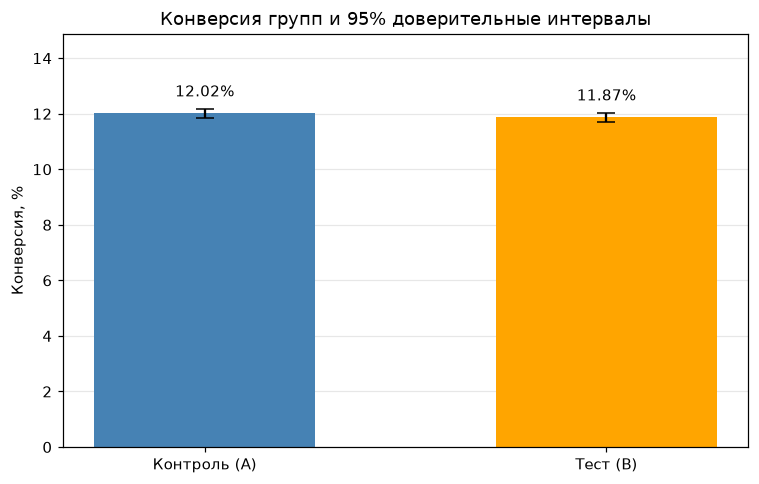

In [23]:
# Сравниваем конверсии групп с интервалами неопределённости.
group_intervals = np.array([wilson_interval(x_a, n_a), wilson_interval(x_b, n_b)])
rates = np.array([cr_a, cr_b])
rate_errors = np.vstack([rates - group_intervals[:, 0], group_intervals[:, 1] - rates]) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(LABELS, rates * 100, color=COLORS, width=0.55, yerr=rate_errors, capsize=6)
for i, rate in enumerate(rates):
    ax.annotate(f"{rate:.2%}", (i, group_intervals[i, 1] * 100), xytext=(0, 8), textcoords="offset points", ha="center")
ax.set(title="Конверсия групп и 95% доверительные интервалы", ylabel="Конверсия, %")
ax.set_ylim(0, max(group_intervals[:, 1]) * 100 * 1.22)
save_plot(fig, "conversion_rate.png")


### 7.2. Размеры групп после очистки

Показываем число уникальных пользователей, вошедших в основной анализ.


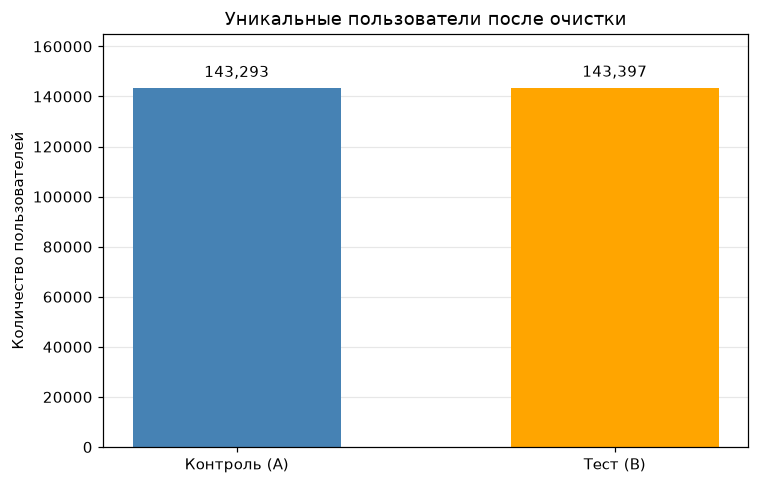

In [24]:
# Показываем размеры контрольной и тестовой групп.
fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(LABELS, [n_a, n_b], color=COLORS, width=0.55)
ax.bar_label(bars, labels=[f"{n_a:,}", f"{n_b:,}"], padding=5)
ax.set(title="Уникальные пользователи после очистки", ylabel="Количество пользователей")
ax.set_ylim(0, max(n_a, n_b) * 1.15)
save_plot(fig, "group_sizes.png")


### 7.3. Эффект и минимально полезный рост

Сопоставляем 95% интервал эффекта с нулевой разницей и бизнес-порогом +1 п.п.


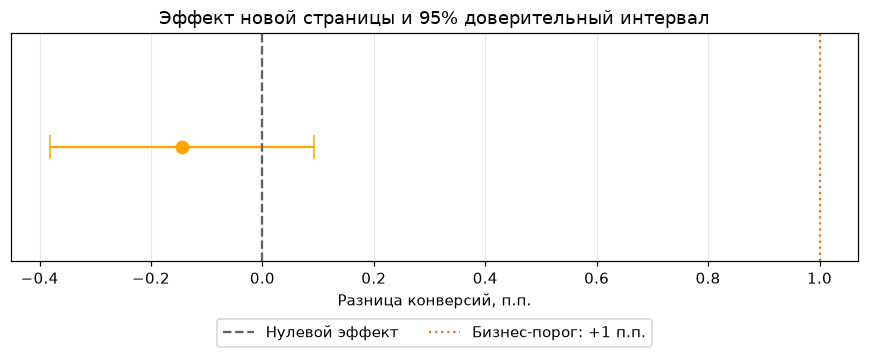

In [25]:
# Отмечаем оценку эффекта, доверительный интервал и два порога для принятия решения.
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.errorbar(effect * 100, 0, xerr=critical_z * se_effect * 100, fmt="o", color=COLORS[1], capsize=8, markersize=8)
ax.axvline(0, color="#59636E", linestyle="--", label="Нулевой эффект")
ax.axvline(BUSINESS_THRESHOLD * 100, color="#D18426", linestyle=":", label="Бизнес-порог: +1 п.п.")
ax.set(title="Эффект новой страницы и 95% доверительный интервал", xlabel="Разница конверсий, п.п.", yticks=[])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2)
save_plot(fig, "confidence_interval.png")


## 8. Практическая значимость

Условный бизнес-порог — рост на +1 п.п. Нижняя граница интервала выше порога
поддерживает полезный рост; верхняя ниже порога не поддерживает рост такого размера.
Если порог внутри интервала, результат относительно него остаётся неопределённым.


In [26]:
# Сравниваем весь доверительный интервал с заранее заданным бизнес-порогом.
if ci_low > BUSINESS_THRESHOLD:
    business_status = "Весь интервал выше бизнес-порога: полезный рост поддерживается данными."
elif ci_high < BUSINESS_THRESHOLD:
    business_status = "Верхняя граница ниже бизнес-порога: рост на +1 п.п. не поддерживается данными."
else:
    business_status = "Интервал пересекает бизнес-порог: данных недостаточно для уверенного решения о пользе."
print(business_status)
print(f"Точечный эффект: {effect * 100:+.4f} п.п.; порог: +{BUSINESS_THRESHOLD * 100:.2f} п.п.")


Верхняя граница ниже бизнес-порога: рост на +1 п.п. не поддерживается данными.
Точечный эффект: -0.1447 п.п.; порог: +1.00 п.п.


**Допущение:** +1 п.п. — выбранный минимально полезный эффект, а не рассчитанный MDE
при заданной мощности. Экономическую целесообразность внедрения нужно отдельно
проверять с учётом дохода, затрат и других продуктовых метрик.


## 9. Выводы и рекомендации

Объединяем размер эффекта, статистическую и практическую значимость.
Итоговый текст рассчитывается по данным при запуске ноутбука; условный SRM
блокирует уверенную рекомендацию о внедрении.


In [27]:
# Формируем итоговые показатели и бизнес-рекомендацию по рассчитанным результатам.
if srm_flag:
    recommendation = "Приостановить решение о внедрении: проверить плановую пропорцию групп, назначение пользователей и потери данных."
elif significant and ci_low > BUSINESS_THRESHOLD:
    recommendation = "Новая версия — кандидат на внедрение: данные поддерживают рост выше бизнес-порога. Перед внедрением подтвердить качество эксперимента и проверить другие продуктовые метрики."
elif significant and effect < 0:
    recommendation = "Не внедрять новую версию: в очищенной выборке обнаружено статистически значимое снижение конверсии."
elif ci_high < BUSINESS_THRESHOLD:
    recommendation = "Не внедрять новую версию ради роста на +1 п.п.: текущий интервал не поддерживает улучшение выбранного размера. Пересмотреть дизайн страницы."
else:
    recommendation = "Не принимать решение о внедрении по текущим данным: результат относительно бизнес-порога неопределён. Спланировать следующий эксперимент с нужной мощностью."

stat_text = "обнаружена статистически значимая разница" if significant else "статистически значимая разница не обнаружена"
relative_text = f"{relative_lift:+.2%}" if np.isfinite(relative_lift) else "не определён"
display(Markdown(f"""
### Результат анализа

- В очищенной выборке **{len(clean):,} уникальных пользователей**.
- Конверсия A: **{cr_a:.2%}**; конверсия B: **{cr_b:.2%}**.
- Абсолютный эффект B − A: **{effect * 100:+.4f} п.п.**; относительный эффект: **{relative_text}**.
- Двусторонний z-тест: **p-value = {p_value:.6g}**; {stat_text} при α = {ALPHA}.
- 95% доверительный интервал: **[{ci_low * 100:+.4f}; {ci_high * 100:+.4f}] п.п.**
- {business_status}

**Рекомендация:** {recommendation}

**Ограничения:** учебный источник; плановое распределение 50/50 принято условно;
неизвестны полный журнал рандомизации и окно конверсии. Исключение проблемных пользователей
может повлиять на состав выборки. Выводы условны и не доказывают причинный эффект при нарушениях дизайна.
"""))



### Результат анализа

- В очищенной выборке **286,690 уникальных пользователей**.
- Конверсия A: **12.02%**; конверсия B: **11.87%**.
- Абсолютный эффект B − A: **-0.1447 п.п.**; относительный эффект: **-1.20%**.
- Двусторонний z-тест: **p-value = 0.232288**; статистически значимая разница не обнаружена при α = 0.05.
- 95% доверительный интервал: **[-0.3821; +0.0927] п.п.**
- Верхняя граница ниже бизнес-порога: рост на +1 п.п. не поддерживается данными.

**Рекомендация:** Не внедрять новую версию ради роста на +1 п.п.: текущий интервал не поддерживает улучшение выбранного размера. Пересмотреть дизайн страницы.

**Ограничения:** учебный источник; плановое распределение 50/50 принято условно;
неизвестны полный журнал рандомизации и окно конверсии. Исключение проблемных пользователей
может повлиять на состав выборки. Выводы условны и не доказывают причинный эффект при нарушениях дизайна.


## Ограничения анализа

- Датасет учебный; результат не относится к реальной компании.
- Плановая пропорция групп 50/50 принята условно.
- Полный журнал рандомизации и окно конверсии неизвестны.
- Проблемные пользователи исключены по выбранному правилу; это может изменить состав выборки.
- Вывод относится к очищенной выборке и зависит от независимости наблюдений и корректности дизайна.
- Бизнес-порог +1 п.п. задан как учебное допущение.
- Стоимость внедрения, доход и другие продуктовые метрики не анализировались.

## Источники

- [Датасет A/B Testing](https://www.kaggle.com/datasets/zhangluyuan/ab-testing)
- [SciPy: нормальное распределение](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html)
- [SciPy: критерий согласия χ²](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.chisquare.html)
